## Zbiór danych mushroom

In [48]:
import matplotlib.pyplot as plt

from id4 import Node, buildTree, predict
import pandas as pd
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import math
import numpy as np
from sklearn.metrics import classification_report, accuracy_score

In [23]:
data = pd.read_csv("./mushrooms.csv")
train_data, test_data = train_test_split(data, test_size=0.3, random_state=0)
X_train = train_data.drop(columns=["class"], axis=1)
Y_train = train_data["class"]
X_test = test_data.drop(columns=["class"], axis=1)
Y_test = test_data["class"]

Node.all_classes = list(Y_train.unique())
Node.all_attributes = list(X_train.keys())
for k in X_train.keys():
    Node.possible_values_attribute[k] = list(X_train[k].unique())


# Rozkład klas

<AxesSubplot: xlabel='class', ylabel='Count'>

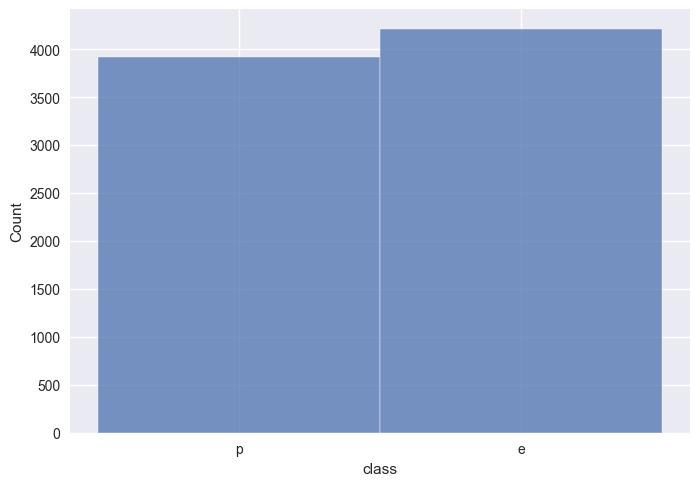

In [24]:
import seaborn
seaborn.histplot(data["class"])

## Uczenie całym zbiorem

In [28]:
tree_batch = Node(Node.all_attributes)

# train tree by batch
tree_batch = buildTree(train_data, tree_batch)
y_test_pred = predict(test_data, tree_batch)
y_train_pred = predict(train_data, tree_batch)

## Dokładność 100%

W tym konkretnym zbiorze danych jest to osiągalne. Dodatkowy sanity-check: drzewo decyzyjne z funkcji bibliotecznej również osiągnęło ten wynik.

In [29]:
print(classification_report(Y_test, y_test_pred))
print(classification_report(Y_train, y_train_pred))

              precision    recall  f1-score   support

           e       1.00      1.00      1.00      1272
           p       1.00      1.00      1.00      1166

    accuracy                           1.00      2438
   macro avg       1.00      1.00      1.00      2438
weighted avg       1.00      1.00      1.00      2438

              precision    recall  f1-score   support

           e       1.00      1.00      1.00      2936
           p       1.00      1.00      1.00      2750

    accuracy                           1.00      5686
   macro avg       1.00      1.00      1.00      5686
weighted avg       1.00      1.00      1.00      5686



## Uczenie batchami

In [31]:
batches = [1000, 500, 200, 100, 50, 25, 10, 5, 1]
scores_test = {batch: [] for batch in batches}
scores_train = {batch: [] for batch in batches}
# train tree by single instances
for batch_size in batches:
    tree_samples = Node(Node.all_attributes)
    print("Batch size: ",batch_size)
    for i in tqdm(range(math.ceil(len(train_data) / batch_size))):
        rows = train_data[i*batch_size:i*batch_size+batch_size]
        #r_df = pd.DataFrame(rows.to_frame().T)
        tree_samples = buildTree(rows, tree_samples)
        y_pred = predict(test_data, tree_samples)
        y_train_pred = predict(train_data, tree_samples)
        scores_test[batch_size].append(accuracy_score(Y_test, y_pred))
        scores_train[batch_size].append(accuracy_score(Y_train, y_train_pred))
    y_test_pred = predict(test_data, tree_samples)
    y_train_pred = predict(train_data, tree_samples)
    print(classification_report(Y_test, y_test_pred))
    print(classification_report(Y_train, y_train_pred))

Batch size:  1000


100%|██████████| 6/6 [00:19<00:00,  3.24s/it]


Batch size:  500


100%|██████████| 12/12 [00:21<00:00,  1.81s/it]


Batch size:  200


100%|██████████| 29/29 [00:26<00:00,  1.09it/s]


... (8 outputs left out)

Batch size:  5


100%|██████████| 1138/1138 [05:43<00:00,  3.31it/s]


Batch size:  1


100%|██████████| 5686/5686 [26:29<00:00,  3.58it/s]


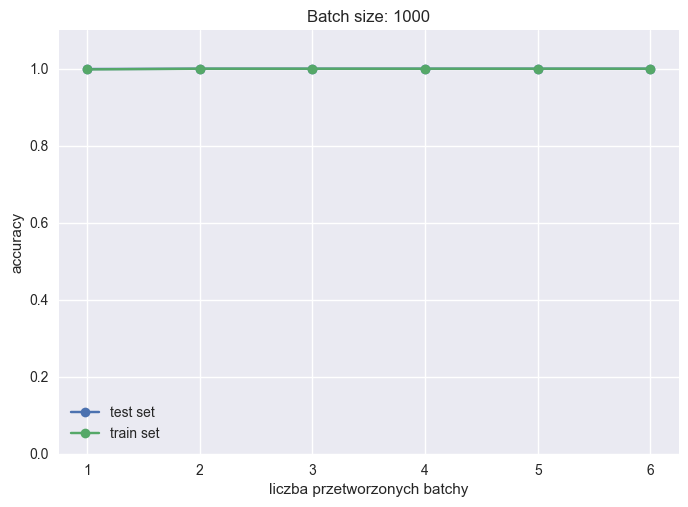

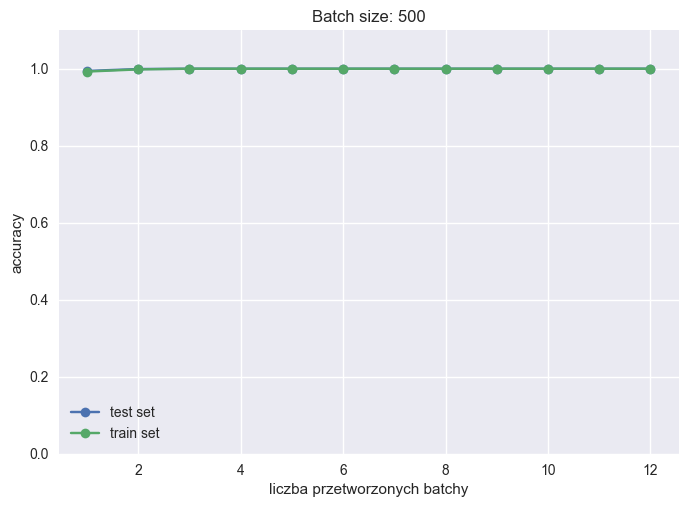

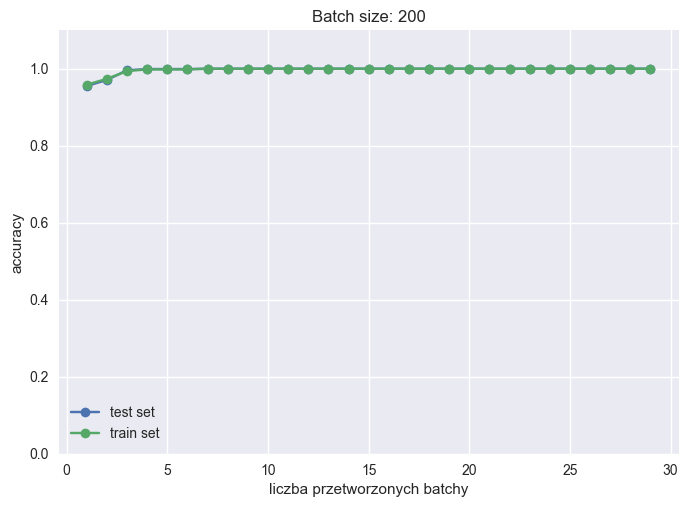

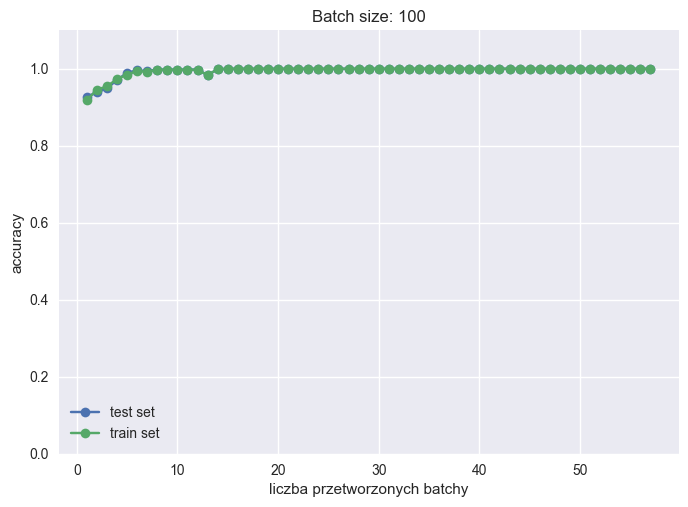

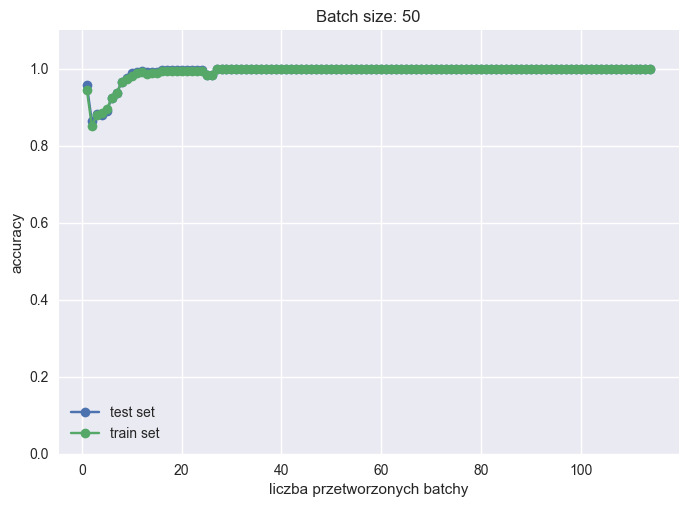

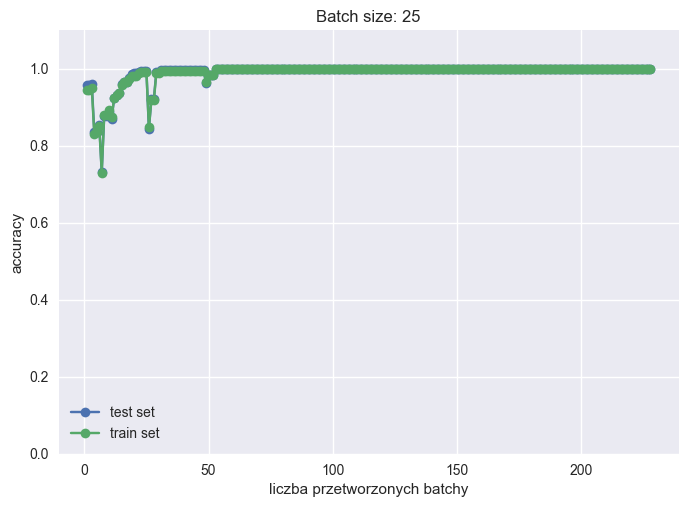

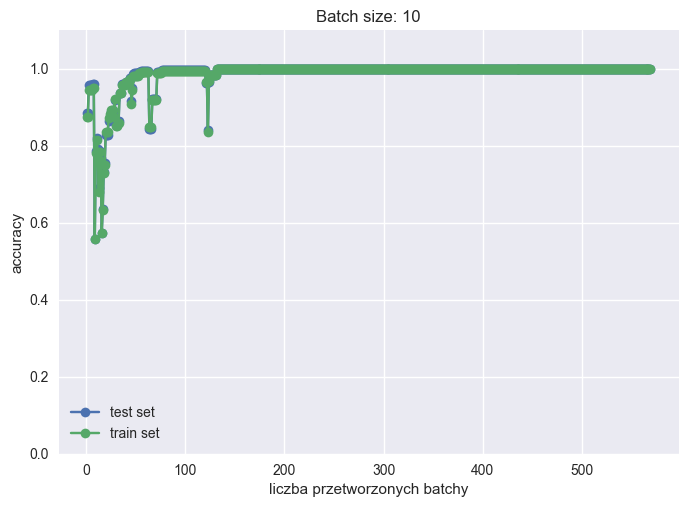

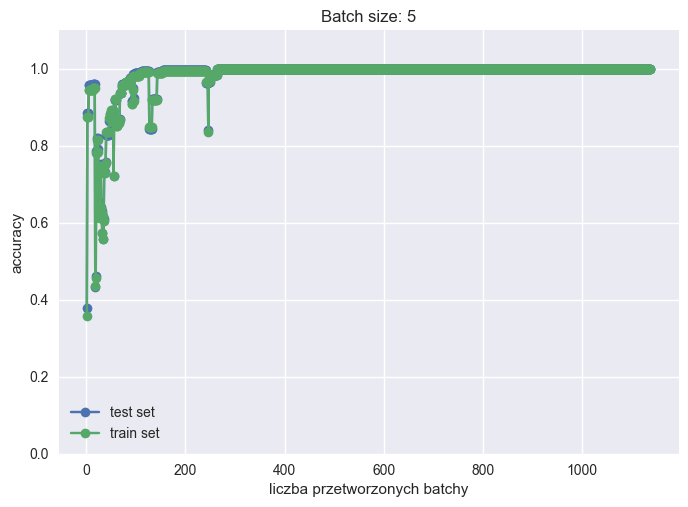

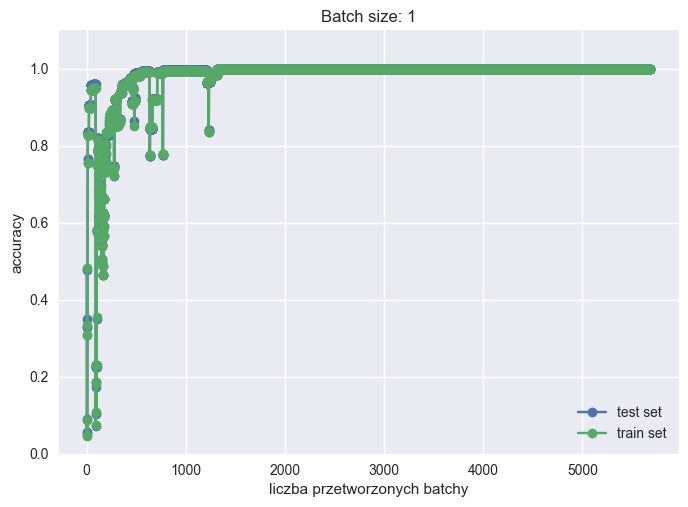

In [44]:
import matplotlib.pyplot as plt
plt.style.use("seaborn-v0_8")

plt.figure()
for (batch, scr_test), (_, scr_train) in zip(scores_test.items(), scores_train.items()):
    x = [i for i in range(1, 1 + math.ceil(len(train_data) / batch))]
    plt.plot(x, scr_test, 'o-')
    plt.plot(x, scr_train, 'o-')
    plt.ylim(0, 1.1)
    plt.xlabel("liczba przetworzonych batchy")
    plt.ylabel("accuracy")
    plt.title(f"Batch size: {batch}")
    plt.legend(["test set", "train set"])
    plt.show()

## Drzewo decyzyjne z scikit-learn

In [9]:
from sklearn.tree import DecisionTreeClassifier

dtc = DecisionTreeClassifier(random_state=0)

X_train_encoded = pd.get_dummies(X_train)
X_test_encoded = pd.get_dummies(X_test)
Y_train_encoded = pd.get_dummies(Y_train)
Y_test_encoded = pd.get_dummies(Y_test)
dtc.fit(X_train_encoded, Y_train_encoded)

DecisionTreeClassifier(random_state=0)

In [10]:
print(classification_report(Y_test_encoded, dtc.predict(X_test_encoded)))
print(classification_report(Y_train_encoded, dtc.predict(X_train_encoded)))

1.0

## Zbiór danych tic-tac-toe

In [45]:
data = pd.read_csv("./tic-tac-toe.data")
train_data, test_data = train_test_split(data, test_size=0.2, random_state=0)
X_train = train_data.drop(columns=["class"], axis=1)
Y_train = train_data["class"]
X_test = test_data.drop(columns=["class"], axis=1)
Y_test = test_data["class"]

Node.all_classes = list(Y_train.unique())
Node.all_attributes = list(X_train.keys())
for k in X_train.keys():
    Node.possible_values_attribute[k] = list(X_train[k].unique())

## Rozkład klas

<AxesSubplot: xlabel='class', ylabel='Count'>

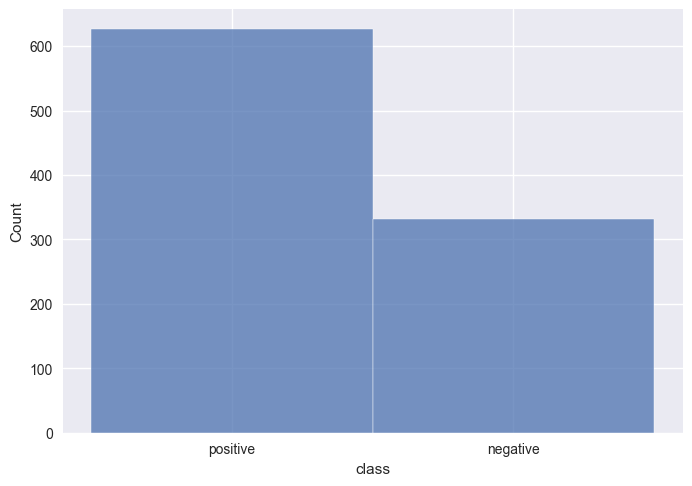

In [46]:
seaborn.histplot(data["class"])

In [50]:
batches = [1000, 500, 200, 100, 50, 25, 10, 5, 1]
scores_train = {batch: [] for batch in batches}
scores_test = {batch: [] for batch in batches}
dataset_loop_nr = 10 # how many times loop through dataset
# train tree by single instances
for batch_size in batches:
    tree_samples = Node(Node.all_attributes)
    print("Batch size: ",batch_size)
    for _ in range(dataset_loop_nr): # Loop through dataset 10 times
        for i in tqdm(range(math.ceil(len(train_data) / batch_size))):
            rows = train_data[i*batch_size:i*batch_size+batch_size]
            #r_df = pd.DataFrame(rows.to_frame().T)
            tree_samples = buildTree(rows, tree_samples)
            y_pred_test = predict(test_data, tree_samples)
            y_pred_train = predict(train_data, tree_samples)
            scores_test[batch_size].append(accuracy_score(Y_test, y_pred_test))
            scores_train[batch_size].append(accuracy_score(Y_train, y_pred_train))
    y_test_pred = np.array(predict(test_data, tree_samples))
    y_train_pred = np.array(predict(train_data, tree_samples))
    print(classification_report(Y_test, y_test_pred))
    print(classification_report(Y_train, y_train_pred))

Batch size:  1000


100%|██████████| 1/1 [00:02<00:00,  2.16s/it]
C:\Users\Wojtek\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\Wojtek\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\Wojtek\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior

              precision    recall  f1-score   support

          -1       0.00      0.00      0.00         0
    negative       0.88      0.82      0.85        74
    positive       0.90      0.89      0.89       118

    accuracy                           0.86       192
   macro avg       0.59      0.57      0.58       192
weighted avg       0.89      0.86      0.88       192

              precision    recall  f1-score   support

    negative       1.00      1.00      1.00       258
    positive       1.00      1.00      1.00       508

    accuracy                           1.00       766
   macro avg       1.00      1.00      1.00       766
weighted avg       1.00      1.00      1.00       766

Batch size:  500


100%|██████████| 2/2 [00:02<00:00,  1.10s/it]
C:\Users\Wojtek\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\Wojtek\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\Wojtek\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior

              precision    recall  f1-score   support

          -1       0.00      0.00      0.00         0
    negative       0.87      0.84      0.86        74
    positive       0.90      0.88      0.89       118

    accuracy                           0.86       192
   macro avg       0.59      0.57      0.58       192
weighted avg       0.89      0.86      0.88       192

              precision    recall  f1-score   support

          -1       0.00      0.00      0.00         0
    negative       0.97      0.98      0.98       258
    positive       0.99      0.97      0.98       508

    accuracy                           0.98       766
   macro avg       0.65      0.65      0.65       766
weighted avg       0.98      0.98      0.98       766

Batch size:  200


100%|██████████| 4/4 [00:02<00:00,  1.64it/s]
C:\Users\Wojtek\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\Wojtek\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\Wojtek\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior

... (10 outputs left out)

              precision    recall  f1-score   support

          -1       0.00      0.00      0.00         0
    negative       0.87      0.80      0.83        74
    positive       0.89      0.86      0.87       118

    accuracy                           0.83       192
   macro avg       0.59      0.55      0.57       192
weighted avg       0.88      0.83      0.86       192

              precision    recall  f1-score   support

          -1       0.00      0.00      0.00         0
    negative       0.96      0.95      0.95       258
    positive       0.98      0.95      0.97       508

    accuracy                           0.95       766
   macro avg       0.65      0.63      0.64       766
weighted avg       0.97      0.95      0.96       766

Batch size:  1


100%|██████████| 766/766 [00:35<00:00, 21.79it/s]

              precision    recall  f1-score   support

          -1       0.00      0.00      0.00         0
    negative       0.87      0.81      0.84        74
    positive       0.90      0.86      0.88       118

    accuracy                           0.84       192
   macro avg       0.59      0.56      0.57       192
weighted avg       0.89      0.84      0.86       192

              precision    recall  f1-score   support

          -1       0.00      0.00      0.00         0
    negative       0.97      0.97      0.97       258
    positive       0.99      0.96      0.97       508

    accuracy                           0.96       766
   macro avg       0.65      0.64      0.65       766
weighted avg       0.98      0.96      0.97       766




C:\Users\Wojtek\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\Wojtek\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
C:\Users\Wojtek\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, l

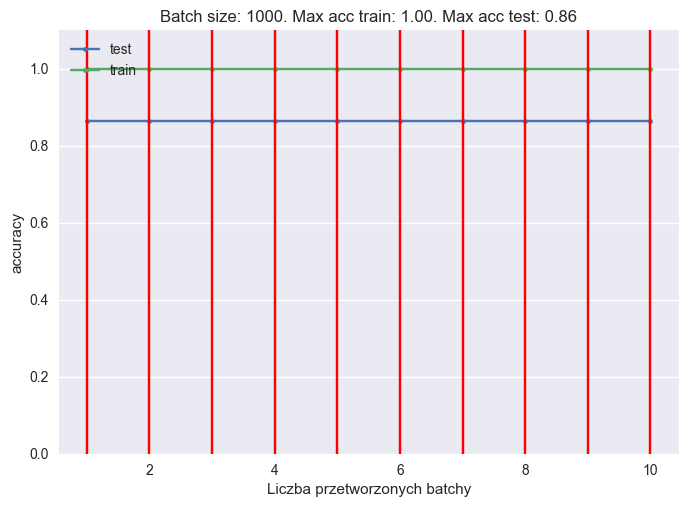

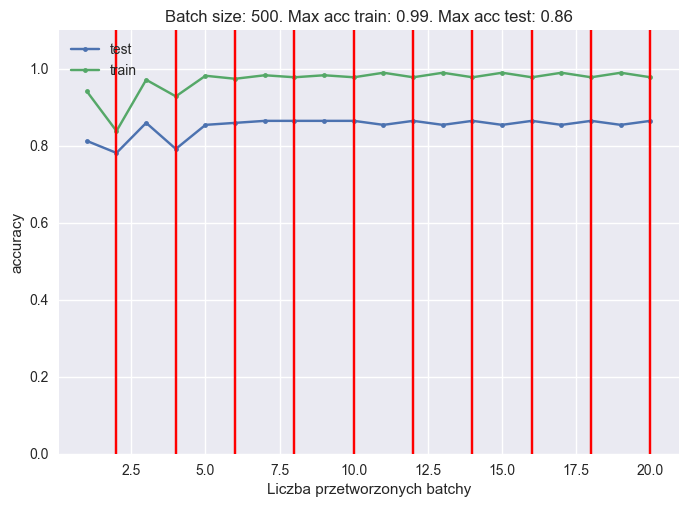

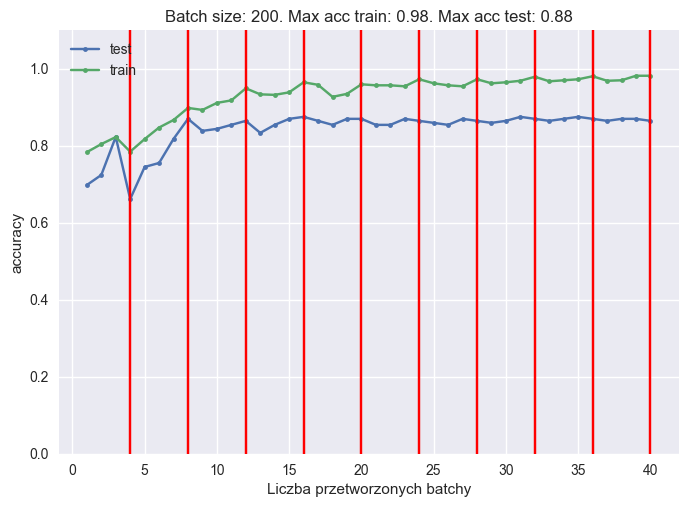

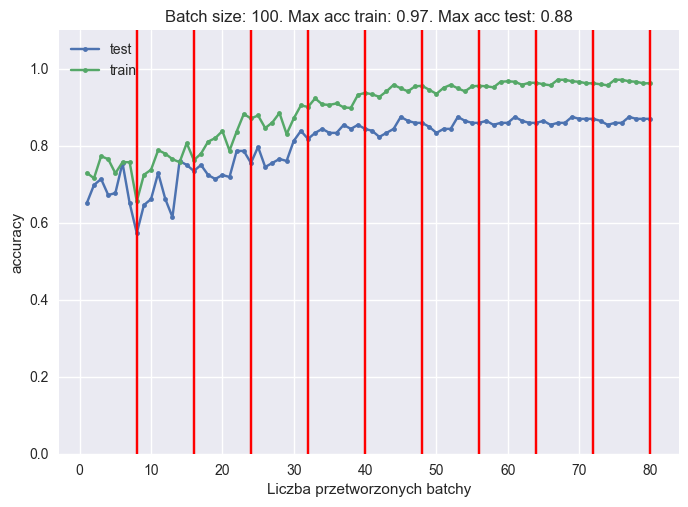

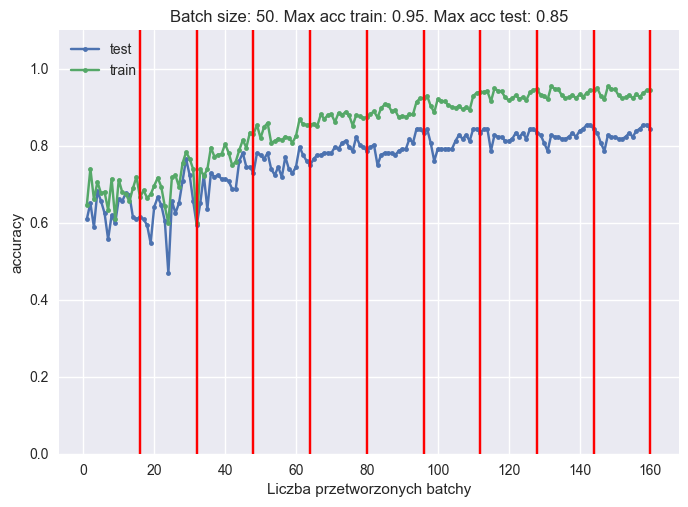

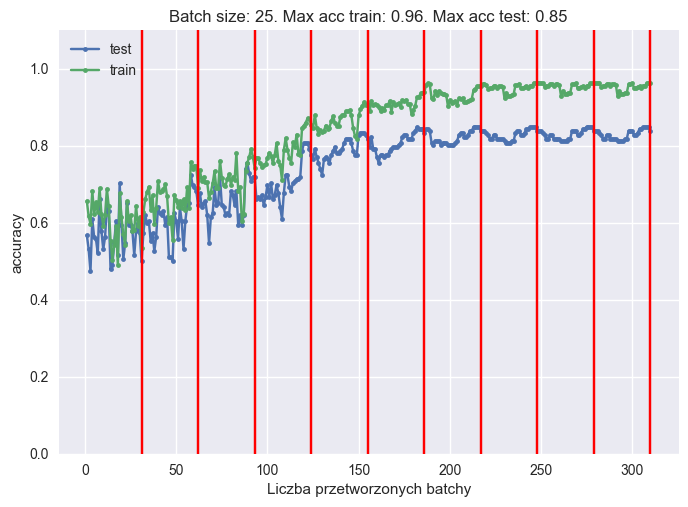

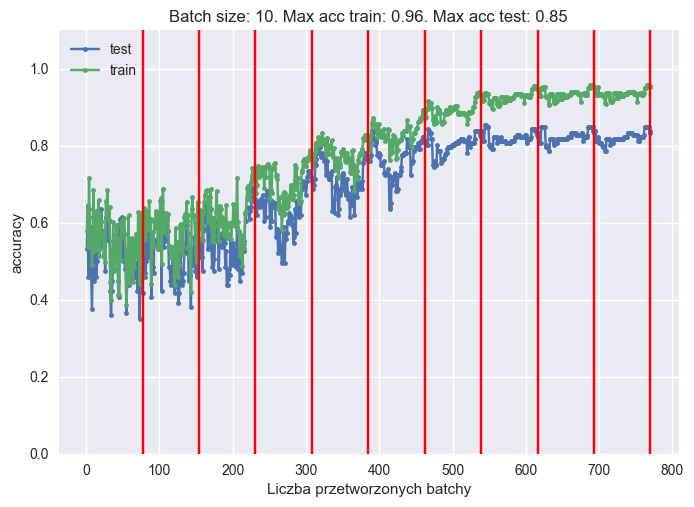

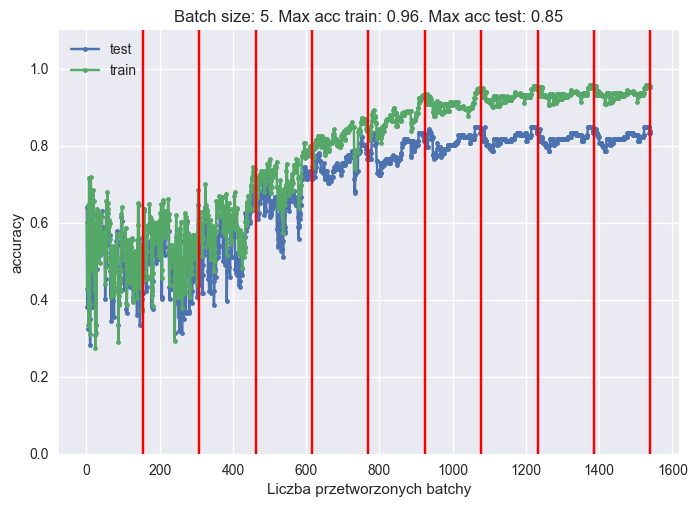

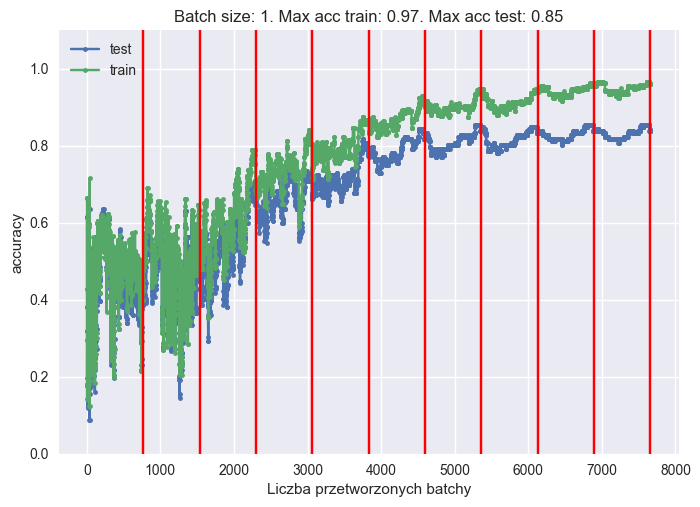

In [62]:
for (batch, scr_test), (_, scr_train) in zip(scores_test.items(), scores_train.items()):
    plt.figure()
    x = np.linspace(start=1, stop=len(scr_train), num=len(scr_train))
    plt.plot(x, scr_test, '.-')
    plt.plot(x, scr_train, '.-')
    plt.xlabel("Liczba przetworzonych batchy")
    plt.ylabel("accuracy")
    plt.legend(["test", "train"], loc='upper left')
    plt.ylim(0, 1.1)
    for i in range(1, dataset_loop_nr+1):
        plt.axvline(i*math.ceil(len(train_data) / batch), color='red')
    plt.title(f"Batch size: {batch}. Max acc train: {max(scr_train):.2f}. Max acc test: {max(scr_test):.2f}")
    plt.show()

## Drzewo decyzyjne z scikit-learn

In [16]:
dtc = DecisionTreeClassifier(random_state=0)
X_train_encoded = pd.get_dummies(X_train)
X_test_encoded = pd.get_dummies(X_test)
Y_train_encoded = pd.get_dummies(Y_train)
Y_test_encoded = pd.get_dummies(Y_test)
dtc.fit(X_train_encoded, Y_train_encoded)
y_pred = dtc.predict(X_test_encoded)
accuracy_score(Y_test_encoded, y_pred)

0.9427083333333334